# Werkplaats blok 1 Lineaire regressie
We gaan eerst weer de data inlezen uit een Excel-bestand en vervolgens schonen.


# Importeren van data
Data inlezen doen we met de pandas-datareader. Die gaan we dus eerst installeren:

In [ ]:
! pip install pandas-datareader==0.10.0

Looking in indexes: https://pypi.org/simple, https://us-python.pkg.dev/colab-wheels/public/simple/
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 109.5/109.5 KB 3.6 MB/s eta 0:00:00
  Attempting uninstall: pandas-datareader
    Found existing installation: pandas-datareader 0.9.0
    Uninstalling pandas-datareader-0.9.0:
      Successfully uninstalled pandas-datareader-0.9.0


Vervolgens kunnen we de library importeren met import pandas as pd. We importeren ook gelijk de library matplotlib, zodat we later grafieken kunnen maken.

In [15]:
import pandas as pd
import matplotlib.pyplot as plt # we gebruiken plt als afkorting om rechtstreeks met matplotlib te praten

En nu kunnen we de data inlezen:

In [ ]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [ ]:
rel_data_path = "/content/drive/MyDrive/vustudentanalytics.xlsx"

In [ ]:
data = pd.read_excel(rel_data_path)
data

,sex,age,agegr,placesize,region,edu,eduspec,socprof,unempdur,income,...,workab,wkabdur,wkabint,wkabintdur,emcc,englang,height,weight,bmi,Column1
0,FEMALE,57,45-59,"URBAN 100,000-200,000",Lubuskie,VOCATIONAL/GRAMMAR,services for the population and transport serv...,RETIRED,0,800.0,...,NO,-8,NO,NaN,NaN,NONE,170.0,89.0,"30,79585",30.795848
1,MALE,20,16-24,RURAL AREAS,Podlaskie,VOCATIONAL/GRAMMAR,no specialisation,PUPIL OR STUDENT,-8,350.0,...,NO,-8,NO,NaN,NaN,ACTIVE,187.0,82.0,"23,44934",23.449341
2,FEMALE,18,16-24,"URBAN 500,000 AND OVER",Mazowieckie,VOCATIONAL/GRAMMAR,no specialisation,PUPIL OR STUDENT,-8,NaN,...,NaN,-8,NO,NaN,NaN,ACTIVE,165.0,50.0,"18,36547",18.365473
3,FEMALE,78,65+,RURAL AREAS,Podlaskie,PRIMARY/NO EDUCATION,no specialisation,RETIRED,-8,900.0,...,NO,-8,NO,NaN,NaN,NONE,160.0,78.0,"30,46875",30.468750
4,FEMALE,54,45-59,"URBAN 100,000-200,000",Zachodnio-pomorskie,VOCATIONAL/GRAMMAR,"agriculture, forestry, fishing",SELF-EMPLOYED,-8,1500.0,...,NO,-8,NO,NaN,NaN,NONE,158.0,50.0,"20,02884",20.028842
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,MALE,56,45-59,"URBAN 20,000-100,000",Swietokrzyskie,SECONDARY,technical science,EMPLOYED IN PRIVATE SECTOR,-8,2500.0,...,NO,-8,NO,NaN,NaN,NONE,176.0,NaN,NaN,NaN
4996,FEMALE,59,45-59,RURAL AREAS,Swietokrzyskie,SECONDARY,"agriculture, forestry, fishing",OTHER ECONOMICALLY INACTIVE,-8,-8.0,...,NO,-8,NO,NaN,NaN,NONE,164.0,80.0,"29,74420",29.744200
4997,FEMALE,20,16-24,RURAL AREAS,Kujawsko-pomorskie,SECONDARY,computer science,EMPLOYED IN PRIVATE SECTOR,0,1000.0,...,NO,-8,NO,NaN,NaN,ACTIVE,160.0,50.0,"19,53125",19.531250
4998,MALE,34,25-34,RURAL AREAS,Dolnoslaskie,SECONDARY,"agriculture, forestry, fishing",EMPLOYED IN PUBLIC SECTOR,0,2600.0,...,NO,-8,NO,NaN,NaN,NONE,178.0,82.0,"25,88057",25.880571


# Schonen van data
Als we kijken naar de data die we vanuit Excel hebben ingelezen, zien we dat er een aantal dingen mis gaan.

Ten eerste zijn de namen van de kolommen niet direct duidelijk. Daarnaast wordt het met 35 kolommen ook een beetje onoverzichtelijk.

Als tweede zijn er de NaN die we op verschillende plekken zien. NaN staat voor "Not a Number", dus we hebben voor dit stuk in het data frame geen getallen om in te vullen.

Gelukkig hebben we ook voor al deze problemen een oplossing. Sommige oplossingen zijn vrij eenvoudig, maar andere zijn wat complexer.

## Data filteren
We hebben het probleem dat onze data een heleboel kolommen heeft die we bij het onderzoeken van onze hypothesen wellicht niet allemaal gaan gebruiken. Eigenlijk willen we die er uit filteren.

We zouden met de .drop("kolomnaam", axis=1) functie wel kolommen kunnen verwijderen, maar met 35 kolommen is dat best wat werk. In dit geval is het makkelijker om met .loc[:, ["Kolom1", "Kolom2", ...]] de kolommen te selecteren die we willen houden.

In [ ]:
data_gefilterd = data.loc[:, ["age", "income"]]
data_gefilterd

,age,income
0,57,800.0
1,20,350.0
2,18,NaN
3,78,900.0
4,54,1500.0
...,...,...
4995,56,2500.0
4996,59,-8.0
4997,20,1000.0
4998,34,2600.0


Hier hoort natuurlijk een fijn grafiekje bij:

Text(0.5, 1.0, 'Inkomen en geslacht')

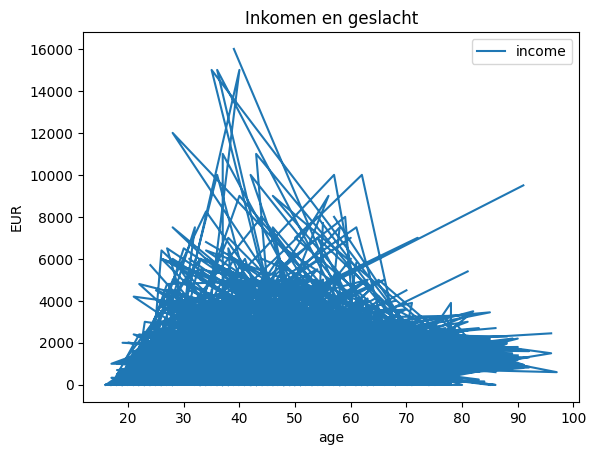

In [ ]:
data_gefilterd.plot(x="age", y="income")
plt.ylabel("EUR")
plt.title("Inkomen en geslacht")

Conclusie?

## NaN
Bepalen wat je het beste kunt doen met NaNs (plekken waar we geen waardes hebben) is een van de lastigere dingen aan data opschonen.

De keuzes die je maakt kunnen veel invloed hebben op het resultaat dat je uiteindelijk krijgt, terwijl je dat soms niet meer door hebt. Daarom is de keuze wat je doet met NaNs heel lastig en ook heel belangrijk.
<p>
Uiteindelijk zijn er 2 mogelijkheden. We kunnen de data weggooien, of we kunnen nieuwe data er bij maken.

Om data weg te gooien hebben we de .dropna() functie. Hierdoor wordt iedere rij waar minstens 1 NaN in zit verwijdert. Hierdoor zijn er geen NaNs meer, maar verwijderen we ook data die soms wel goed was.

In [ ]:
nans_verwijderd = data_gefilterd.dropna()
nans_verwijderd

,age,income
0,57,800.0
1,20,350.0
3,78,900.0
4,54,1500.0
5,20,-8.0
...,...,...
4994,68,-8.0
4995,56,2500.0
4996,59,-8.0
4997,20,1000.0


We houden van de 5.000 regels 4.317 over! Nu nog de -8 verwijderen uit de 'income' kolom:

In [ ]:
nans_verwijderd = nans_verwijderd[nans_verwijderd.income != -8]
nans_verwijderd

,age,income
0,57,800.0
1,20,350.0
3,78,900.0
4,54,1500.0
6,39,2000.0
...,...,...
4991,48,3000.0
4992,28,1800.0
4995,56,2500.0
4997,20,1000.0


Met deze 3.714 rijen kunnnen we nu de lineaire regressie gaan draaien.

# Enkelvoudige lineaire regressie met kwantitatieve data
Eerst lezen we de benodigde libraries voor de regressie-analyse in:

In [16]:
import statsmodels.api as sm
import numpy as np

from scipy import stats
from sklearn.linear_model import LinearRegression

Daarna kiezen we de x en y variabelen op basis van de zelf opgestelde hypothese:<br>
- x: de oorzaak of verklarende variabele<br>
- y: het gevolg of de te verklaren variabele

In [ ]:
X = nans_verwijderd[["age"]]
y = nans_verwijderd[["income"]]

X2 = sm.add_constant(X)
est = sm.OLS(y, X2)
est2 = est.fit()
print(est2.summary())

                            OLS Regression Results                            
Dep. Variable:                 income   R-squared:                       0.016
Model:                            OLS   Adj. R-squared:                  0.016
Method:                 Least Squares   F-statistic:                     61.31
Date:                Sun, 01 Mar 2026   Prob (F-statistic):           6.32e-15
Time:                        13:00:40   Log-Likelihood:                -31647.
No. Observations:                3714   AIC:                         6.330e+04
Df Residuals:                    3712   BIC:                         6.331e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       2108.9115     62.936     33.509      0.0

We onderzoeken of er een verband is tussen leeftijd en inkomen. Het model is:<br>
inkomen = 2.108,91 - 9,01 x leeftijd<br>
<p>
Er lijkt dus een negatief verband te zijn tussen leeftijd en inkomen: hoe ouder je wordt, hoe minder je gaat verdienen.<br>
<p>
Is het model geldig?<br>
De p-waarde van de variabele 'leeftijd' is kleiner dan 0,05, dus dat is ok.<br>
Helaas is de R-kwadraat waarde 0,016 = kleiner dan 0,1: er is dus geen (statistisch) verband in deze dataset tussen leeftijd en inkomen.


## Intermezzo: wat staat er allemaal bij de OLS Regression Results?
**Aan de linkerkant:**<br>
Dep.Variable = de afhankelijke variabele<br>
Model = welk type regressie-model wordt er gebruikt, hier: Ordinary Least Squares<br>
Method = welke methode wordt gebruikt voor het schatten van de regressie-lijn<br>
No. Observations = steekproefgrootte (of aantal datapunten of regels van het dataframe)<br>
Df Residuals = Degree of freedom is the number of independent observations on the basis of which the sum of squares is calculated. Te berekenen door: Degrees of freedom (Df)  = N – K<br>
N = sample size (no. of observations) and  K = number of variables + 1<br>
Df Model = Degrees of freedom van het model = K - 1<br>
Covariance Type = robust of nonrobust, maar wat dat precies betekent?<br>
https://en.wikipedia.org/wiki/Heteroskedasticity-consistent_standard_errors
<br>
<br>
**Aan de rechterkant:**<br>
R-squared = de determinatiecoefficient, hoeveel % van de variatie in de y-variabele (gevolg) wordt verklaard door de x-variabele(n)(oorza(a)k(en))<br>
Adj. R-squared = te gebruiken bij meervoudige regressie, om te kijken of alle x-en bijdragen aan het verklaren van de variatie in y.<br>
F-statistic =  F test tells the goodness of fit of a regression. The test is similar to the t-test or other tests for the hypothesis.<br>
Prob (F-statistic) =  de kans op een uitkomst gelijk aan of groter dan de F-statistic. Als deze kans erg klein is, verwerpen we de Ho-hypothese dat de coefficienten gelijk zijn aan 0 (vergelijkbaar met de t-test en de p-waarden).<br>
Log-Likelihood =  een maatstaf voor hoe waarschijnlijk het is dat de steekproefdata hoort bij het gevonden regressiemodel.<br>
Bayes: P(data | model).<br>
https://en.wikipedia.org/wiki/Likelihood_function#Log-likelihood<br>
AIC = the [Akaike Information Criteria (AIC) ](https://en.wikipedia.org/wiki/Akaike_information_criterion) is an estimator of prediction error and thereby relative quality of statistical models for a given set of data. Given a collection of models for the data, AIC estimates the quality of each model, relative to each of the other models. Thus, AIC provides a means for model selection. The lower, the better.<br>
BIC = the [Bayesian Information Criterion (BIC)](https://en.wikipedia.org/wiki/Bayesian_information_criterion) or Schwarz information criterion (also SIC, SBC, SBIC) is a criterion for model selection among a finite set of models; models with lower BIC are generally preferred. It is based, in part, on the likelihood function and it is closely related to the Akaike information criterion (AIC).
<br>
<br>
**In het midden:**<br>
coef = de coefficienten van de regressielijn. Bij een enkelvoudige regressie y = ax + b is 'const' de constante b en a het getal dat staat bij de onafhankelijke variabele x (= age)(in het voorbeeld boven: -9,01).<br>
std err = de standaardafwijking van de coefficienten.<br>
t = de t-waarde van de t-test op de coefficienten, waarbij de Ho-hypothese is dat de coefficient een waarde van 0 heeft.<br>
P>|t| = de kans op een uitkomst groter of gelijk aan de t-waarde. Dit noemen we de p-waarde, om een regressiemodel geldig te laten zijn, mag deze niet groter zijn dan 0,05.<br>
[0.025      0.975] = 95%-betrouwbaarheidsinterval voor de coefficienten.<br>
<br>
**Onder:**<br>
Omnibus = describes the normalcy of the distribution of our residuals using skew and kurtosis as measurements. A 0 would indicate perfect normalcy.<br>
Prob(Omnibus) = is a statistical test measuring the probability the residuals are normally distributed. A 1 would indicate perfectly normal distribution.<br>
Skew = is a measurement of symmetry in our data, with 0 being perfect symmetry.<br>
Kurtosis = measures the peakiness of our data, or its concentration around 0 in a normal curve. A kurtosis of 3 implies a normal distribution. Higher kurtosis implies fewer outliers.<br>
<br>
Durbin-Watson = the [Durbin Watson (DW) statistic](https://www.investopedia.com/terms/d/durbin-watson-statistic.asp) is a test for autocorrelation in the residuals from a statistical model or regression analysis. The Durbin-Watson statistic will always have a value ranging between 0 and 4. A value of 2.0 indicates there is no autocorrelation detected in the sample. Values from 0 to less than 2 point to positive autocorrelation and values from 2 to 4 means negative autocorrelation.<br>
Jarque-Bera (JB) = the [Jarque–Bera test](https://en.wikipedia.org/wiki/Jarque%E2%80%93Bera_test) is a goodness-of-fit test of whether sample data have the skewness and kurtosis matching a normal distribution. The test is named after Carlos Jarque and Anil K. Bera. The test statistic is always nonnegative. If it is far from zero, it signals the data do not have a normal distribution.<br>
Prob(JB) = de kans op een uitkomst groter of gelijk aan de JB-testwaarde. Als deze kans erg klein is, verwerpen we de Ho-hypothese dat de data normaal verdeeld zijn.<br>
Cond. No. = is a measurement of the sensitivity of our model as compared to the size of changes in the data it is analyzing. Multicollinearity is strongly implied by a high condition number.
Multicollinearity = a term to describe two or more independent variables that are strongly related to each other and are falsely affecting our predicted variable by redundancy.<br>
<br>
Bronnen:<br>
https://medium.com/swlh/interpreting-linear-regression-through-statsmodels-summary-4796d359035a<br>
https://jyotiyadav99111.medium.com/statistics-how-should-i-interpret-results-of-ols-3bde1ebeec01


# Enkelvoudige lineaire regressie: de Excel-manier
We maken een spreidingsdiagram met op de x-as de leeftijd en op de y-as het inkomen:

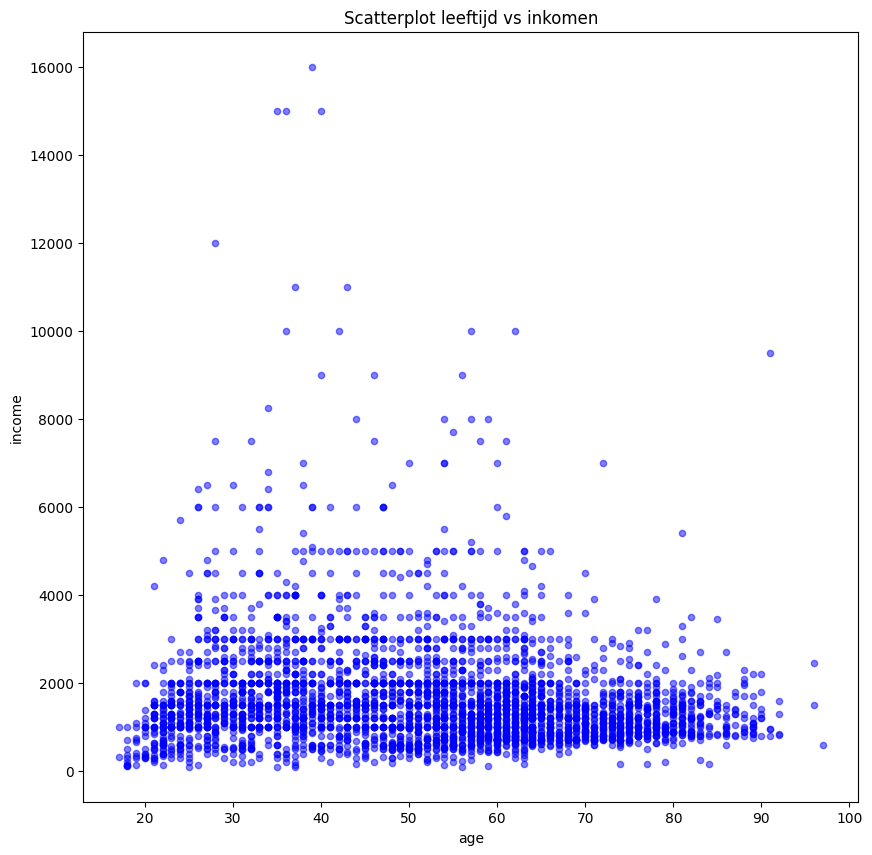

In [ ]:
nans_verwijderd.plot(kind="scatter", x="age", y="income", color="blue", alpha=0.5, figsize=(10,10))
plt.title("Scatterplot leeftijd vs inkomen")
plt.show()

Er lijkt op het oog niet direct een verband te zijn. Eens kijken of de regressie-analyse dat bevestigt:

In [ ]:
linear_regression = LinearRegression()

X = nans_verwijderd.loc[:,["age"]]
y = nans_verwijderd.loc[:,["income"]]

linear_regression.fit(X,y)

print("De richtingscoefficient is", linear_regression.coef_)
print("De constante is", linear_regression.intercept_)
print("De determinatiecoefficient R2 is", linear_regression.score(X, y))

De richtingscoefficient is [[-9.01579992]]
De constante is [2108.91148571]
De determinatiecoefficient R2 is 0.01624788533980126


De R-kwadraat is 0,01: er is geen verband tussen leeftijd en het inkomen. <br>

We voegen nu de regressielijn toe aan de grafiek:

/tmp/ipython-input-306/508849980.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  nans_verwijderd.loc[:, "Prediction"] = linear_regression.predict(nans_verwijderd.loc[:, ['age']])


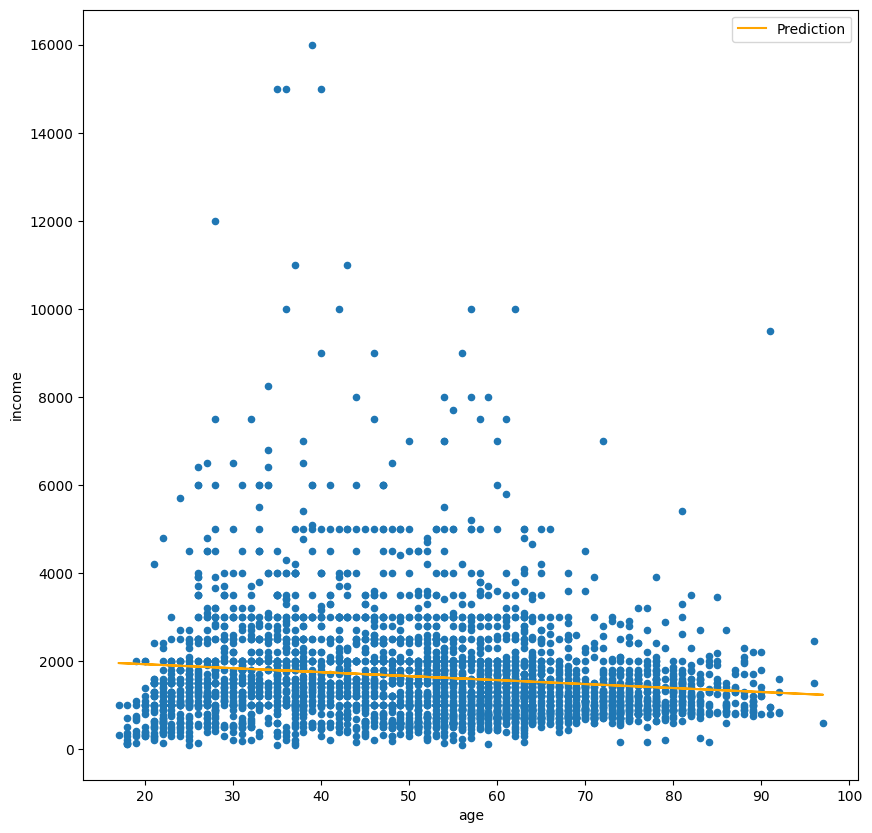

In [ ]:
nans_verwijderd.loc[:, "Prediction"] = linear_regression.predict(nans_verwijderd.loc[:, ['age']])

grafiek = nans_verwijderd.plot(x="age", y="income", kind='scatter')
nans_verwijderd.plot(x="age", y="Prediction", kind="line", color="orange", ax=grafiek, label="Prediction", figsize=(10,10) )
plt.legend()
plt.show()

Mooi plaatje, de vergelijking van de lijn is ook hier:<br>
inkomen = 2.108,91 - 9,01 x leeftijd

# Enkelvoudige lineaire regressie met kwalitatieve data
We kunnen ook een regressie-analyse doen met kwalitatieve (ook wel: categoriale) data. Daarvoor zijn 2 manieren:<br>
- Ordinal encoding<br>
- One-hot encoding<br>






## Ordinal encoding
De eerste techniek is de Ordinal Encoding. Deze gebruikt, zoals de naam al zegt, ordinaalgetallen om de verschillende categorieen aan te duiden. Dit houdt in dat een categorie "de eerste" is, een ander "de tweede", en eentje "de derde".

Hiermee worden de categorieen dus genummerd, en wordt dat nummer als _feature_ gebruikt om de lineaire regressie op te doen. Hierbij is het dus wel van belang dat de nummers ook logisch zijn. Als locatie "Florida" de orde 1 krijgt, en locatie "Texas" 2, dan is automatisch Texas 2x zoveel als Florida.

Als een lineaire regressie dan een coefficient moet leren, is er geen logica meer van opvolgende waardes. Gebruik dit daarom alleen op punten waar er inderdaad een volgorde zit aan de categoriale waardes. Dit kan bijvoorbeeld bij de kolom agegr uit de vu-dataset.

In [ ]:
data_agegr = data.loc[:, ["agegr", "income"]].dropna()
data_agegr = data_agegr[data_agegr.income != -8]
data_agegr

,agegr,income
0,45-59,800.0
1,16-24,350.0
3,65+,900.0
4,45-59,1500.0
6,35-44,2000.0
...,...,...
4991,45-59,3000.0
4992,25-34,1800.0
4995,45-59,2500.0
4997,16-24,1000.0


Je ziet hier dat de leeftijden niet als individuele getallen zijn aangegeven maar als leeftijdsgroepen waar personen in vallen.

Dit betekent dat er inderdaad een logische volgorde is. Namelijk:

16-24 -> 25-34 -> 35-44 -> 45-59-> 60-64 -> 65+

Om hier de ranken [1, 2, 3, 4, 5, 6] aan te geven gebruiken we de `OrdinalEncoder` van `sklearn.preprocessing`.

Bij het aanmaken van de `OrdinalEncoder` moeten we de categorieen in de juiste volgorde aangeven. Daarna kunnen we met de `.fit_transform()` functie de kolom _encoden_.

Let op! We moeten bij het aangeven van de categorieen en bij het transformeren de dubbele blokhaken gebruiken!

In [ ]:
from sklearn.preprocessing import OrdinalEncoder

ordinal_encoder = OrdinalEncoder(categories=[['16-24', '25-34', '35-44', '45-59', '60-64', '65+']]) # Let op! Dubbele blokhaak

ordinal_encoder.fit_transform(data_agegr.loc[:, ["agegr"]]) # Let op! Dubbele blokhaak

array([[3.],
       [0.],
       [5.],
       ...,
       [3.],
       [0.],
       [1.]])

Deze waardes kunnen we ook allemaal naar een nieuwe kolom van het data frame schrijven. Daardoor kunnen we het data frame later makkelijker gebruiken voor de lineaire regressie.

In [ ]:
data_agegr["leeftijd ordinaal"] = ordinal_encoder.fit_transform(data_agegr.loc[:, ["agegr"]]) # Let op! Dubbele blokhaak

data_agegr.loc[:, ["income", "agegr", "leeftijd ordinaal"]]

,income,agegr,leeftijd ordinaal
0,800.0,45-59,3.0
1,350.0,16-24,0.0
3,900.0,65+,5.0
4,1500.0,45-59,3.0
6,2000.0,35-44,2.0
...,...,...,...
4991,3000.0,45-59,3.0
4992,1800.0,25-34,1.0
4995,2500.0,45-59,3.0
4997,1000.0,16-24,0.0


Nu kunnen we met enkelvoudige regressie kijken of er een verband is tussen de leeftijdsgroepen en het inkomen:

In [ ]:
X = data_agegr[["leeftijd ordinaal"]]
y = data_agegr[["income"]]

X2 = sm.add_constant(X)
est = sm.OLS(y, X2)
est2 = est.fit()
print(est2.summary())

                            OLS Regression Results                            
Dep. Variable:                 income   R-squared:                       0.014
Model:                            OLS   Adj. R-squared:                  0.014
Method:                 Least Squares   F-statistic:                     52.46
Date:                Sun, 01 Mar 2026   Prob (F-statistic):           5.32e-13
Time:                        13:02:24   Log-Likelihood:                -31635.
No. Observations:                3712   AIC:                         6.327e+04
Df Residuals:                    3710   BIC:                         6.329e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
const              1926.6765     44.10

We zien ook hier het negatieve verband tussen leeftijd en inkomen: hoe hoger de (ordinale) leeftijd, hoe lager het inkomen.

## One-hot encoding
Met one-hot encoding maken we een nieuwe kolom voor iedere mogelijke waarde en zetten we een 1 of een 0 om aan te geven of het die waarde is. Bij "sex" kan je dus een kolom "sex_MALE" en "sex_FEMALE" krijgen met 1 en 0. Deze kolommen kunnen we dan gebruiken voor de Lineaire Regressie. Hoewel we dit ook met `sklearn` zouden kunnen doen, heeft `Pandas` er een makkelijkere functie voor.
<p>
De `pd.get_dummies()` functie maakt op basis van een kolom zo'n one-hot encoding data frame waar iedere kolom een unieke categorie is. Door een `prefix` mee te geven kunnen we voor iedere kolom de naam van de oorspronkelijke kolom mee geven. Zo houden we onze data overzichtelijker.

In [ ]:
one_hot = pd.get_dummies(data.loc[:, ["sex"]], dtype=int, prefix="sex")
one_hot

,sex_FEMALE,sex_MALE
0,1,0
1,0,1
2,1,0
3,1,0
4,1,0
...,...,...
4995,0,1
4996,1,0
4997,1,0
4998,0,1


In the regression setting, a factor variable with P distinct levels is usually represented by a matrix with only P – 1 columns. This is because a regression model typically includes an intercept term. With an intercept, once you have defined the values for P – 1 binaries, the value for the Pth is known and could be considered redundant.

Adding the Pth column will cause a **multicollinearity** error.

**Multicollinearity** = a term to describe two or more independent variables that are strongly related to each other and are falsely affecting our predicted variable by redundancy.

Bij (meervoudige) regressie geldt dus: als je P categorische variabelen hebt, houd je na hercodering P-1 categorieen over.

Door aan de get_dummies functie de 'drop_first=True' regel toe te voegen, vervalt de eerste dummie-kolom. In dit voorbeeld houden we dan alleen de 'sex_MALE' kolom over.

In [ ]:
one_hot = pd.get_dummies(data.loc[:, ["sex"]], drop_first=True, dtype=int, prefix="sex")
one_hot

,sex_MALE
0,0
1,1
2,0
3,0
4,0
...,...
4995,1
4996,0
4997,0
4998,1


**Let Op:** er is geen informatie verloren gegaan! Als er in de regel een 0 staat, is het geslacht vrouw, als er een 1 staat is het geslacht man.

Deze `get_dummies()` functie geeft een apart data frame terug. Het is voor onze lineaire regressie makkelijker als we de kolommen van dit nieuwe data frame samenvoegen met ons bestaande data frame (nans_verwijderd).

Hiervoor kunnen we de `pd.concat()` functie gebruiken. We kunnen daar met blokhaken de data frames aangeven die we willen samenvoegen. Daarna kunnen we met de `axis` parameter aangeven of we de rijen of de kolommen willen samenvoegen. Met `axis=0` voegen we data frames per rij samen, en met `axis=1` per kolom.

Omdat we in dit geval per kolom willen samenvoegen komen we op het volgende uit:

In [ ]:
df_met_one_hot = pd.concat([nans_verwijderd, one_hot], axis=1)

df_met_one_hot = df_met_one_hot.dropna()

df_met_one_hot = df_met_one_hot[['age', 'income', 'sex_MALE']]

df_met_one_hot

,age,income,sex_MALE
0,57.0,800.0,0
1,20.0,350.0,1
3,78.0,900.0,0
4,54.0,1500.0,0
6,39.0,2000.0,0
...,...,...,...
4991,48.0,3000.0,0
4992,28.0,1800.0,0
4995,56.0,2500.0,1
4997,20.0,1000.0,0


Nu zien we dat ons data frame 2 nieuwe kolommen heeft die de leeftijd en het inkomen van een persoon aangeven.
<p>
Eens kijken of er een verband is tussen inkomen en geslacht. We gebruiken de kolom sex_MALE als onafhankelijke variabele `X` en het income als onze afhankelijke variabele `y`:

In [ ]:
X = df_met_one_hot[["sex_MALE"]]
y = df_met_one_hot[["income"]]

X2 = sm.add_constant(X)
est = sm.OLS(y, X2)
est2 = est.fit()
print(est2.summary())

                            OLS Regression Results                            
Dep. Variable:                 income   R-squared:                       0.032
Model:                            OLS   Adj. R-squared:                  0.032
Method:                 Least Squares   F-statistic:                     123.6
Date:                Sun, 01 Mar 2026   Prob (F-statistic):           2.91e-28
Time:                        13:06:31   Log-Likelihood:                -31616.
No. Observations:                3714   AIC:                         6.324e+04
Df Residuals:                    3712   BIC:                         6.325e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       1443.8198     26.591     54.297      0.0

Conclusie: op basis van de coefficient verdienen mannen gemiddeld TEN OPZICHTE VAN vrouwen 442 (euro's) meer. <br>Het model is geldig (p-waarde kleiner dan 0,05), maar er is (R-kwadraat van 0,032) statistisch geen verband.

# Meervoudige lineaire regressie
Kunnen we het inkomen ook voorspellen op basis van leeftijd en geslacht?<br>
Jazeker, dat heet meervoudige regressie:

In [ ]:
X = df_met_one_hot[["age","sex_MALE"]]
y = df_met_one_hot[["income"]]

X2 = sm.add_constant(X)
est = sm.OLS(y, X2)
est2 = est.fit()
print(est2.summary())

                            OLS Regression Results                            
Dep. Variable:                 income   R-squared:                       0.045
Model:                            OLS   Adj. R-squared:                  0.044
Method:                 Least Squares   F-statistic:                     86.94
Date:                Sun, 01 Mar 2026   Prob (F-statistic):           1.26e-37
Time:                        13:07:29   Log-Likelihood:                -31592.
No. Observations:                3714   AIC:                         6.319e+04
Df Residuals:                    3711   BIC:                         6.321e+04
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       1867.1027     66.144     28.228      0.0

Is het model geldig? Wat is de bijbehorende vergelijking?

Aan jullie de uitdaging om voor al jullie hypothesen de regressie-analyse uit te voeren (enkel-of meervoudig, kwantitatief of kwalitatief) en vooral niet te vergeten: wat is nu de CONCLUSIE??
<p>
Succes!

# Extra: stepwise selection

In [ ]:
data_clean = data.dropna()
data_clean = data_clean[data_clean.income != -8]
data_clean

,sex,age,agegr,placesize,region,edu,eduspec,socprof,unempdur,income,...,workab,wkabdur,wkabint,wkabintdur,emcc,englang,height,weight,bmi,Column1
525,MALE,34,25-34,"URBAN BELOW 20,000",Podlaskie,SECONDARY,technical science,PUPIL OR STUDENT,-8,3000.0,...,NO,-8,"YES, TO EU COUNTRY",IT DEPENDS,IRELAND,ACTIVE,182.0,80.0,"24,15167",24.151673
566,FEMALE,46,45-59,"URBAN BELOW 20,000",Lubuskie,SECONDARY,social sciences,EMPLOYED IN PRIVATE SECTOR,12,1000.0,...,YES,1,"YES, TO EU COUNTRY",IT DEPENDS,GERMANY,NONE,165.0,62.0,"22,77319",22.773186
1289,MALE,31,25-34,"URBAN BELOW 20,000",Zachodnio-pomorskie,SECONDARY,no specialisation,EMPLOYED IN PRIVATE SECTOR,6,3000.0,...,YES,3,"YES, TO EU COUNTRY",IT DEPENDS,NETHERLANDS,NONE,175.0,78.0,"25,46939",25.469388
1405,MALE,45,45-59,"URBAN 100,000-200,000",Slaskie,PRIMARY/NO EDUCATION,no specialisation,SELF-EMPLOYED,16,350.0,...,NO,-8,"YES, TO EU COUNTRY",IT DEPENDS,GREAT BRITAIN,NONE,176.0,70.0,"22,59814",22.598140
1585,MALE,32,25-34,RURAL AREAS,Mazowieckie,VOCATIONAL/GRAMMAR,technical science,EMPLOYED IN PRIVATE SECTOR,0,2000.0,...,YES,24,"YES, TO EU COUNTRY",LESS THAN 1 TO 2 YEARS,GREAT BRITAIN,PASSIVE,176.0,74.0,"23,88946",23.889463
1818,FEMALE,58,45-59,"URBAN 500,000 AND OVER",Malopolskie,SECONDARY,production and processing,EMPLOYED IN PUBLIC SECTOR,-8,1600.0,...,NO,-8,"YES, TO EU COUNTRY",IT DEPENDS,ITALY,NONE,158.0,94.0,"37,65422",37.654222
1832,FEMALE,24,16-24,"URBAN 20,000-100,000",Pomorskie,SECONDARY,services for the population and transport serv...,EMPLOYED IN PRIVATE SECTOR,0,1600.0,...,NO,-8,"YES, TO EU COUNTRY",MORE THAN 2 YEARS,FRANCE,ACTIVE,176.0,69.0,"22,27531",22.275310
2007,FEMALE,65,65+,"URBAN 20,000-100,000",Slaskie,SECONDARY,social sciences,RETIRED,24,1300.0,...,NO,-8,"YES, TO EU COUNTRY",LESS THAN 1 YEAR,ITALY,NONE,160.0,61.0,"23,82812",23.828125
2093,MALE,56,45-59,RURAL AREAS,Dolnoslaskie,SECONDARY,technical science,EMPLOYED IN PRIVATE SECTOR,0,2000.0,...,NO,-8,"YES, TO EU COUNTRY",IT DEPENDS,BELGIUM,PASSIVE,175.0,68.0,"22,20408",22.204082
2206,FEMALE,51,45-59,"URBAN BELOW 20,000",Mazowieckie,VOCATIONAL/GRAMMAR,social sciences,EMPLOYED IN PRIVATE SECTOR,0,1000.0,...,NO,-8,"YES, TO EU COUNTRY",LESS THAN 1 TO 2 YEARS,GERMANY,NONE,160.0,49.0,"19,14062",19.140625


## Stepwise Selection using Akaike Information Criterion

In [ ]:
import pandas as pd
import numpy as np
from sklearn.metrics import mean_squared_error
from sklearn.linear_model import LinearRegression

def AIC_score(y_true, y_pred, model, df=None):
    # AIC (Akaike Information Criterion) implementation
    # K is the number of parameters in the model. For linear regression, it's typically (number of features + 1 for intercept).
    # For the null model, df should be 1 (for the mean).
    if df is None and model is not None:
        k = len(model.coef_) + 1 if model.fit_intercept else len(model.coef_)
    elif df is not None:
        k = df
    else:
        raise ValueError("Either a model or df must be provided.")

    n = len(y_true)
    if n == 0: # Handle empty input to prevent division by zero
        return float('inf')

    mse = mean_squared_error(y_true, y_pred)
    # If mse is very close to zero, log(0) would be -inf. Handle this case.
    if mse < 1e-10: # A very small threshold to consider it effectively zero
        return -2 * 0 + 2 * k # If MSE is zero, log(MSE) goes to -infinity. This is a heuristic.

    aic = n * np.log(mse) + 2 * k
    return aic


def stepwise_selection(X_columns, train_model, score_model, verbose=True):
    initial_list = []
    # Convert X_columns to a list if it's not already, and ensure it's iterable
    current_X_columns = list(X_columns) if not isinstance(X_columns, list) else X_columns

    best_variables = initial_list.copy()
    best_score = score_model(None, []) # Score for the null model
    best_model = None

    while True:
        changed = False
        # Forward step
        scores_with_candidates = []
        for candidate in current_X_columns:
            if candidate not in best_variables:
                test_variables = best_variables + [candidate]
                model = train_model(test_variables)
                score = score_model(model, test_variables)
                scores_with_candidates.append((score, candidate, model))

        if scores_with_candidates:
            best_new_score, best_new_candidate, best_new_model = min(scores_with_candidates, key=lambda x: x[0])

            if best_new_score < best_score:
                best_score = best_new_score
                best_variables.append(best_new_candidate)
                best_model = best_new_model
                changed = True
                if verbose:
                    print(f'Add  {{best_new_candidate}} with AIC: {{best_new_score:.4f}}')

        # Backward step (optional, but good for robustness)
        if best_variables:
            scores_with_candidates = []
            for candidate_to_remove in best_variables:
                test_variables = [var for var in best_variables if var != candidate_to_remove]
                model = train_model(test_variables)
                score = score_model(model, test_variables)
                scores_with_candidates.append((score, candidate_to_remove, model))

            if scores_with_candidates:
                best_removed_score, removed_candidate, removed_model = min(scores_with_candidates, key=lambda x: x[0])

                # If removing a variable improves the score significantly, remove it
                # This comparison needs to be carefully handled to avoid infinite loops if scores are very close
                if best_removed_score < best_score and len(best_variables) > 1: # Don't remove if only one variable left
                    best_score = best_removed_score
                    best_variables.remove(removed_candidate)
                    best_model = removed_model
                    changed = True
                    if verbose:
                        print(f'Remove {{removed_candidate}} with AIC: {{best_removed_score:.4f}}')

        if not changed:
            break

    return best_model, best_variables


outcome = 'income'

# --- Data Preprocessing for Stepwise Selection ---
# Start with `data_clean` (which is already globally available and has income -8 filtered out)
processed_df = data_clean.copy()

# Step 1: Handle the BMI columns to ensure they are numeric.
# Prioritize 'Column1' if it's numeric, otherwise convert 'bmi'.
if 'Column1' in processed_df.columns:
    if pd.api.types.is_numeric_dtype(processed_df['Column1']):
        processed_df['bmi_numeric'] = processed_df['Column1'] # Use Column1 as numeric BMI
    else: # If Column1 is not numeric, try to convert it (less likely)
        processed_df['bmi_numeric'] = pd.to_numeric(processed_df['Column1'].astype(str).str.replace(',', '.', regex=False), errors='coerce')
    processed_df = processed_df.drop(columns=['Column1']) # Drop original Column1

if 'bmi' in processed_df.columns and processed_df['bmi'].dtype == 'object':
    # If 'bmi' is object type, convert it to numeric (assuming ',' is decimal separator)
    processed_df['bmi_numeric'] = processed_df['bmi'].astype(str).str.replace(',', '.', regex=False)
    processed_df['bmi_numeric'] = pd.to_numeric(processed_df['bmi_numeric'], errors='coerce')
    processed_df = processed_df.drop(columns=['bmi']) # Drop original string bmi
elif 'bmi' in processed_df.columns and pd.api.types.is_numeric_dtype(processed_df['bmi']) and 'bmi_numeric' not in processed_df.columns: # If bmi was already numeric and not already handled by Column1
    processed_df['bmi_numeric'] = processed_df['bmi']
    processed_df = processed_df.drop(columns=['bmi'])

# Drop rows where bmi_numeric became NaN after conversion or was originally NaN
processed_df.dropna(subset=['bmi_numeric'], inplace=True)


# Step 2: Identify and one-hot encode remaining categorical columns
categorical_cols = processed_df.select_dtypes(include='object').columns

# Apply one-hot encoding to identified categorical columns
# Add a check to avoid get_dummies if no categorical columns are left
if not categorical_cols.empty:
    data_encoded = pd.get_dummies(processed_df, columns=categorical_cols, drop_first=True, dtype=int)
else:
    data_encoded = processed_df.copy() # No categorical columns to encode

# Step 3: Define target variable `y` and feature matrix `X_features_for_stepwise`
y = data_encoded[outcome]
X_features_for_stepwise = data_encoded.drop(columns=[outcome])

# Step 4: Final cleaning for features - drop columns with any non-finite values (NaN, inf)
X_features_for_stepwise = X_features_for_stepwise.replace([np.inf, -np.inf], np.nan)
X_features_for_stepwise.dropna(axis=1, inplace=True) # Drop columns that contain NaNs

# Step 5: Align y with X_features_for_stepwise based on common index
common_index = X_features_for_stepwise.index.intersection(y.index)
X_features_for_stepwise = X_features_for_stepwise.loc[common_index]
y = y.loc[common_index]

y.dropna(inplace=True) # Final check for NaNs in target
X_features_for_stepwise = X_features_for_stepwise.loc[y.index] # Re-align X after y.dropna()

# Rename the 'bmi_numeric' column to just 'bmi' for cleaner output if it was chosen
# This step should happen *before* passing X_features_for_stepwise.columns to stepwise_selection
if 'bmi_numeric' in X_features_for_stepwise.columns:
    X_features_for_stepwise = X_features_for_stepwise.rename(columns={'bmi_numeric': 'bmi'})


def train_model(variables):
    if len(variables) == 0:
        return None
    model = LinearRegression()
    # Use X_features_for_stepwise here as the input feature set
    model.fit(X_features_for_stepwise[variables], y)
    return model

def score_model(model, variables):
    if len(variables) == 0:
        return AIC_score(y, [y.mean()] * len(y), model=None, df=1)
    # Use X_features_for_stepwise here for prediction
    return AIC_score(y, model.predict(X_features_for_stepwise[variables]), model)


best_model, best_variables = stepwise_selection(X_features_for_stepwise.columns,
                                                lambda vars: train_model(vars) if vars else None,
                                                lambda model, vars: score_model(model, vars),
                                                verbose=True)


print()
if best_model:
    # Calculate AIC for the final best model
    final_aic_score = score_model(best_model, best_variables)
    print(f'AIC-score: {final_aic_score:.4f}')
    print(f'Intercept: {best_model.intercept_:.3f}')
    print('Coefficients:')
    for name, coef in zip(best_variables, best_model.coef_):
        print(f' {name}: {coef}')
else:
    print("No best model found (perhaps the null model was best).")
    print(f'Best model is the null model with intercept (mean of income): {y.mean():.3f}')

Add  {best_new_candidate} with AIC: {best_new_score:.4f}
Add  {best_new_candidate} with AIC: {best_new_score:.4f}
Add  {best_new_candidate} with AIC: {best_new_score:.4f}
Add  {best_new_candidate} with AIC: {best_new_score:.4f}
Add  {best_new_candidate} with AIC: {best_new_score:.4f}
Add  {best_new_candidate} with AIC: {best_new_score:.4f}
Add  {best_new_candidate} with AIC: {best_new_score:.4f}
Add  {best_new_candidate} with AIC: {best_new_score:.4f}
Add  {best_new_candidate} with AIC: {best_new_score:.4f}
Add  {best_new_candidate} with AIC: {best_new_score:.4f}
Add  {best_new_candidate} with AIC: {best_new_score:.4f}
Add  {best_new_candidate} with AIC: {best_new_score:.4f}
Add  {best_new_candidate} with AIC: {best_new_score:.4f}
Add  {best_new_candidate} with AIC: {best_new_score:.4f}
Add  {best_new_candidate} with AIC: {best_new_score:.4f}
Add  {best_new_candidate} with AIC: {best_new_score:.4f}
Add  {best_new_candidate} with AIC: {best_new_score:.4f}

AIC-score: -113.4678
Intercept

The final model derived from this process has the following intercept and coefficients for the selected features:

Intercept: 460.357<br>

Coefficients:<br>
agegr_25-34: 1009.534<br>
ls_PLEASED: 1703.459<br>
agegr_45-59: -711.281<br>
eduspec_production and processing: -1163.397<br>
placesize_URBAN BELOW 20,000: 709.732<br>
unempdur: -12.925<br>
placesize_URBAN 20,000-100,000: 458.022<br>
eduspec_no specialisation: 207.156<br>
bmi: 32.126<br>
englang_PASSIVE: -112.085<br>
sex_MALE: -125.257<br>
wkabintdur_IT DEPENDS: 71.481<br>
englang_NONE: -73.700<br>
region_Lubuskie: -33.107<br>
wkabintdur_MORE THAN 2 YEARS: -34.001<br>
ls_MOSTLY DISSATISFIED: -5.118<br>
placesize_URBAN 100,000-200,000: 2.081<br>
<p>
This indicates a more complex model than the simple linear regression with 'age' and 'sex' alone, suggesting that these additional factors contribute to explaining the variation in income.

## Stepwise Selection using Bayesian Information Criterion (BIC)

BIC is another criterion used for model selection, similar to AIC, but it applies a stronger penalty for the number of parameters in the model. This often results in the selection of models with fewer variables, favoring parsimony. The formula for BIC is:

$BIC = n \cdot \ln(\text{MSE}) + k \cdot \ln(n)$

Where:
*   $n$ is the number of observations
*   $\text{MSE}$ is the Mean Squared Error of the model
*   $k$ is the number of parameters in the model (including the intercept)

I've modified the `AIC_score` function to calculate BIC instead, and the `stepwise_selection` process will now use this BIC to evaluate and select the best model.

In [ ]:
import pandas as pd
import numpy as np
from sklearn.metrics import mean_squared_error
from sklearn.linear_model import LinearRegression

def BIC_score(y_true, y_pred, model, df=None):
    # BIC (Bayesian Information Criterion) implementation
    # K is the number of parameters in the model. For linear regression, it's typically (number of features + 1 for intercept).
    # For the null model, df should be 1 (for the mean).
    if df is None and model is not None:
        k = len(model.coef_) + 1 if model.fit_intercept else len(model.coef_)
    elif df is not None:
        k = df
    else:
        raise ValueError("Either a model or df must be provided.")

    n = len(y_true)
    if n == 0: # Handle empty input to prevent division by zero
        return float('inf')

    mse = mean_squared_error(y_true, y_pred)
    # If mse is very close to zero, log(0) would be -inf. Handle this case.
    if mse < 1e-10: # A very small threshold to consider it effectively zero
        # For mse=0, log(mse) is -inf. Handle this by returning a very small BIC equivalent
        return -2 * 0 + k * np.log(n) # Using the structure of AIC for mse=0 but with BIC's penalty

    bic = n * np.log(mse) + k * np.log(n)
    return bic


def stepwise_selection(X_columns, train_model, score_model, verbose=True):
    initial_list = []
    current_X_columns = list(X_columns) if not isinstance(X_columns, list) else X_columns

    best_variables = initial_list.copy()
    best_score = score_model(None, []) # Score for the null model
    best_model = None

    while True:
        changed = False
        # Forward step
        scores_with_candidates = []
        for candidate in current_X_columns:
            if candidate not in best_variables:
                test_variables = best_variables + [candidate]
                model = train_model(test_variables)
                score = score_model(model, test_variables)
                scores_with_candidates.append((score, candidate, model))

        if scores_with_candidates:
            best_new_score, best_new_candidate, best_new_model = min(scores_with_candidates, key=lambda x: x[0])

            if best_new_score < best_score:
                best_score = best_new_score
                best_variables.append(best_new_candidate)
                best_model = best_new_model
                changed = True
                if verbose:
                    print(f'Add  {{best_new_candidate}} with BIC: {{best_new_score:.4f}}')

        # Backward step (optional, but good for robustness)
        if best_variables:
            scores_with_candidates = []
            for candidate_to_remove in best_variables:
                test_variables = [var for var in best_variables if var != candidate_to_remove]
                model = train_model(test_variables)
                score = score_model(model, test_variables)
                scores_with_candidates.append((score, candidate_to_remove, model))

            if scores_with_candidates:
                best_removed_score, removed_candidate, removed_model = min(scores_with_candidates, key=lambda x: x[0])

                # If removing a variable improves the score significantly, remove it
                if best_removed_score < best_score and len(best_variables) > 1:
                    best_score = best_removed_score
                    best_variables.remove(removed_candidate)
                    best_model = removed_model
                    changed = True
                    if verbose:
                        print(f'Remove {{removed_candidate}} with BIC: {{best_removed_score:.4f}}')

        if not changed:
            break

    return best_model, best_variables


outcome = 'income'

# --- Data Preprocessing for Stepwise Selection ---
# Start with `data_clean` (which is already globally available and has income -8 filtered out)
processed_df = data_clean.copy()

# Step 1: Handle the BMI columns to ensure they are numeric.
# Prioritize 'Column1' if it's numeric, otherwise convert 'bmi'.
if 'Column1' in processed_df.columns:
    if pd.api.types.is_numeric_dtype(processed_df['Column1']):
        processed_df['bmi_numeric'] = processed_df['Column1'] # Use Column1 as numeric BMI
    else:
        processed_df['bmi_numeric'] = pd.to_numeric(processed_df['Column1'].astype(str).str.replace(',', '.', regex=False), errors='coerce')
    processed_df = processed_df.drop(columns=['Column1']) # Drop original Column1

if 'bmi' in processed_df.columns and processed_df['bmi'].dtype == 'object':
    processed_df['bmi_numeric'] = processed_df['bmi'].astype(str).str.replace(',', '.', regex=False)
    processed_df['bmi_numeric'] = pd.to_numeric(processed_df['bmi_numeric'], errors='coerce')
    processed_df = processed_df.drop(columns=['bmi']) # Drop original string bmi
elif 'bmi' in processed_df.columns and pd.api.types.is_numeric_dtype(processed_df['bmi']) and 'bmi_numeric' not in processed_df.columns:
    processed_df['bmi_numeric'] = processed_df['bmi']
    processed_df = processed_df.drop(columns=['bmi'])

# Drop rows where bmi_numeric became NaN after conversion or was originally NaN
processed_df.dropna(subset=['bmi_numeric'], inplace=True)


# Step 2: Identify and one-hot encode remaining categorical columns
categorical_cols = processed_df.select_dtypes(include='object').columns

# Apply one-hot encoding to identified categorical columns
if not categorical_cols.empty:
    data_encoded = pd.get_dummies(processed_df, columns=categorical_cols, drop_first=True, dtype=int)
else:
    data_encoded = processed_df.copy() # No categorical columns to encode

# Step 3: Define target variable `y` and feature matrix `X_features_for_stepwise`
y = data_encoded[outcome]
X_features_for_stepwise = data_encoded.drop(columns=[outcome])

# Step 4: Final cleaning for features - drop columns with any non-finite values (NaN, inf)
X_features_for_stepwise = X_features_for_stepwise.replace([np.inf, -np.inf], np.nan)
X_features_for_stepwise.dropna(axis=1, inplace=True) # Drop columns that contain NaNs

# Step 5: Align y with X_features_for_stepwise based on common index
common_index = X_features_for_stepwise.index.intersection(y.index)
X_features_for_stepwise = X_features_for_stepwise.loc[common_index]
y = y.loc[common_index]

y.dropna(inplace=True) # Final check for NaNs in target
X_features_for_stepwise = X_features_for_stepwise.loc[y.index] # Re-align X after y.dropna()

# Rename the 'bmi_numeric' column to just 'bmi' for cleaner output if it was chosen
# This step should happen *before* passing X_features_for_stepwise.columns to stepwise_selection
if 'bmi_numeric' in X_features_for_stepwise.columns:
    X_features_for_stepwise = X_features_for_stepwise.rename(columns={'bmi_numeric': 'bmi'})


def train_model(variables):
    if len(variables) == 0:
        return None
    model = LinearRegression()
    model.fit(X_features_for_stepwise[variables], y)
    return model

def score_model(model, variables):
    if len(variables) == 0:
        return BIC_score(y, [y.mean()] * len(y), model=None, df=1)
    return BIC_score(y, model.predict(X_features_for_stepwise[variables]), model)


best_model, best_variables = stepwise_selection(X_features_for_stepwise.columns,
                                                lambda vars: train_model(vars) if vars else None,
                                                lambda model, vars: score_model(model, vars),
                                                verbose=True)


print()
if best_model:
    # Calculate BIC for the final best model
    final_bic_score = score_model(best_model, best_variables)
    print(f'BIC-score: {final_bic_score:.4f}')
    print(f'Intercept: {best_model.intercept_:.3f}')
    print('Coefficients:')
    for name, coef in zip(best_variables, best_model.coef_):
        print(f' {name}: {coef}')
else:
    print("No best model found (perhaps the null model was best).")
    print(f'Best model is the null model with intercept (mean of income): {y.mean():.3f}')

Add  {best_new_candidate} with BIC: {best_new_score:.4f}
Add  {best_new_candidate} with BIC: {best_new_score:.4f}
Add  {best_new_candidate} with BIC: {best_new_score:.4f}
Add  {best_new_candidate} with BIC: {best_new_score:.4f}
Add  {best_new_candidate} with BIC: {best_new_score:.4f}
Add  {best_new_candidate} with BIC: {best_new_score:.4f}
Add  {best_new_candidate} with BIC: {best_new_score:.4f}
Add  {best_new_candidate} with BIC: {best_new_score:.4f}
Add  {best_new_candidate} with BIC: {best_new_score:.4f}
Add  {best_new_candidate} with BIC: {best_new_score:.4f}
Add  {best_new_candidate} with BIC: {best_new_score:.4f}
Add  {best_new_candidate} with BIC: {best_new_score:.4f}
Add  {best_new_candidate} with BIC: {best_new_score:.4f}
Add  {best_new_candidate} with BIC: {best_new_score:.4f}
Add  {best_new_candidate} with BIC: {best_new_score:.4f}
Add  {best_new_candidate} with BIC: {best_new_score:.4f}
Add  {best_new_candidate} with BIC: {best_new_score:.4f}

BIC-score: -96.4679
Intercept:

## Vergelijk de AIC-resultaten met de BIC-resultaten
That's an interesting observation!<br> After running the stepwise selection with both AIC and BIC, the results show that both criteria selected the exact same 17 variables for the model, with identical intercept and coefficient values.

This means that for this specific dataset and model, even with BIC's stronger penalty for model complexity, all 17 variables were deemed essential to optimize the model's fit and predictive power.

To recap the theoretical difference:

AIC (Akaike Information Criterion) aims to select the model that best explains the data while keeping the number of parameters relatively low. It balances goodness of fit with model complexity.
<p>
BIC (Bayesian Information Criterion) also balances fit and complexity, but it applies a much stronger penalty for each additional parameter. This often leads BIC to select simpler models (with fewer variables) compared to AIC, especially with large datasets.
<p>
In your case, the fact that both yielded the same model suggests that all 17 chosen variables contribute significantly enough that even the stricter BIC found them valuable.

# Logistieke regressie

Logistic regression is a statistical method used for binary classification problems, meaning it predicts the probability that an outcome belongs to one of two categories (e.g., Yes/No, True/False, 0/1). Unlike linear regression, which predicts a continuous outcome, logistic regression transforms the output using a sigmoid function, ensuring the result is a probability between 0 and 1.

When to use it: You typically use logistic regression when your dependent variable (the outcome you are trying to predict) is categorical and binary.

For example:

Predicting customer churn: Will a customer churn (Yes/No)?<br>
Disease prediction: Will a patient have a certain disease (Yes/No)?<br>
Spam detection: Is an email spam (Yes/No)?<br>
Loan default: Will a borrower default on a loan (Yes/No)?
<p>
It's also useful when you want to understand the relationship between independent variables and the probability of a binary outcome, and to quantify the impact of each predictor in terms of odds ratios (as we will calculate for 'Financial_Stress' - see below).

In [17]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [18]:
rel_data_path_2 = "/content/drive/MyDrive/mental_health.csv"

In [19]:
df = pd.read_csv(rel_data_path_2)
df

,Age,Gender,Country,Education,Marital_Status,Income_Level,Employment_Status,Work_Hours_Per_Week,Remote_Work,Job_Satisfaction,...,Ever_Sought_Treatment,On_Therapy_Now,On_Medication,Trauma_History,Social_Support,Close_Friends_Count,Feel_Understood,Loneliness,Discuss_Mental_Health,Has_Mental_Health_Issue
0,40,Male,USA,Some College,Single,Middle,Full-time,27,No,6,...,1,0,0,0,9,3,4,6,Sometimes,1
1,33,Male,India,Bachelor,Married,Middle,Unemployed,47,No,6,...,0,0,0,0,3,2,7,7,Sometimes,1
2,42,Male,Other,High School,Single,Low,Full-time,53,No,1,...,1,0,0,1,5,3,6,9,Sometimes,1
3,53,Male,Germany,Bachelor,Single,Middle,Unemployed,42,No,10,...,0,1,0,0,1,3,10,5,Never,1
4,32,Female,India,Bachelor,Single,High,Student,13,No,4,...,0,0,0,0,1,5,1,6,Sometimes,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,50,Female,India,High School,Divorced,High,Student,42,No,4,...,0,0,0,0,5,5,6,4,Sometimes,1
9996,18,Female,UK,Some College,Divorced,Middle,Full-time,33,Yes,6,...,1,0,0,0,1,3,10,2,Rarely,1
9997,26,Male,Brazil,Master,Married,High,Full-time,34,No,4,...,0,0,0,0,4,6,5,5,Rarely,0
9998,40,Female,Brazil,Some College,Single,Low,Full-time,42,No,3,...,1,0,0,0,5,3,4,1,Sometimes,1


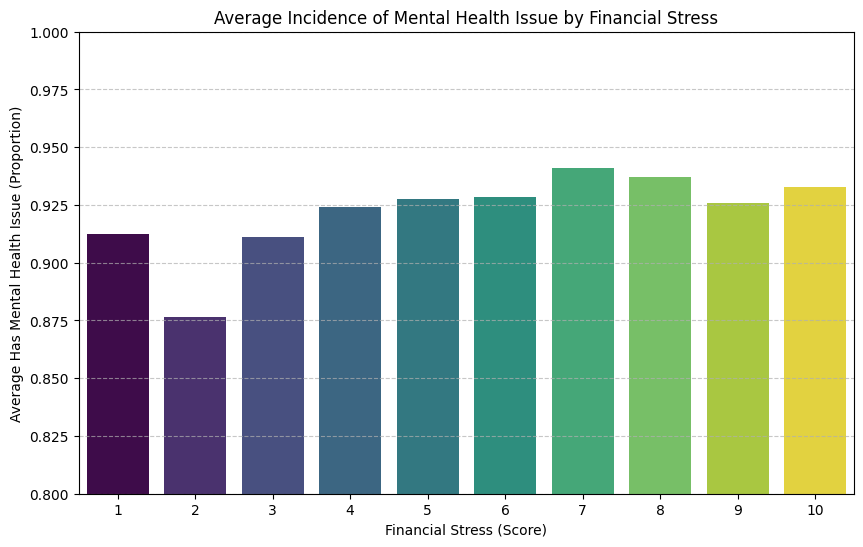

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate the mean of 'Has_Mental_Health_Issue' for each 'Financial_Stress' level
mental_health_by_stress = df.groupby('Financial_Stress')['Has_Mental_Health_Issue'].mean().reset_index()

plt.figure(figsize=(10, 6))
sns.barplot(x='Financial_Stress', y='Has_Mental_Health_Issue', data=mental_health_by_stress, hue='Financial_Stress', palette='viridis', legend=False)
plt.title('Average Incidence of Mental Health Issue by Financial Stress')
plt.xlabel('Financial Stress (Score)')
plt.ylabel('Average Has Mental Health Issue (Proportion)')
plt.ylim(0.8, 1) # Ensure y-axis is between 0.8 and 1 for proportions
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

In [ ]:
import statsmodels.api as sm

# Define the independent variable (X) and dependent variable (y)
X_log = df[['Financial_Stress']]
y_log = df['Has_Mental_Health_Issue']

# Add a constant to the independent variable for the intercept
X_log = sm.add_constant(X_log)

# Fit the logistic regression model
logit_model = sm.Logit(y_log, X_log)
result = logit_model.fit()

# Print the model summary
print(result.summary())

Optimization terminated successfully.
         Current function value: 0.273791
         Iterations 7
                              Logit Regression Results                             
Dep. Variable:     Has_Mental_Health_Issue   No. Observations:                10000
Model:                               Logit   Df Residuals:                     9998
Method:                                MLE   Df Model:                            1
Date:                     Mon, 09 Mar 2026   Pseudo R-squ.:                0.003830
Time:                             09:11:22   Log-Likelihood:                -2737.9
converged:                            True   LL-Null:                       -2748.4
Covariance Type:                 nonrobust   LLR p-value:                 4.468e-06
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
const                2.1508      0.076     28.406      0

The logistic regression model has been successfully fitted. Here's a summary of the results:

Dependent Variable: 'Has_Mental_Health_Issue' (as expected, a binary outcome).
<p>
No. Observations: The model was trained on 10,000 observations.
<p>
Pseudo R-squared: The Pseudo R-squared value is 0.003830, which is quite low. This indicates that 'Financial_Stress' alone explains a very small proportion of the variance in the likelihood of having a mental health issue.
<p>
LLR p-value: The LLR p-value (4.468e-06) is very small (much less than 0.05), indicating that the overall model is statistically significant. This means that 'Financial_Stress' is a significant predictor in this model.
<p>
Coefficients:
<p>
const (Intercept): The coefficient for the intercept is 2.1508 (p-value 0.000). This represents the log-odds of having a mental health issue when 'Financial_Stress' is zero. To get the odds, you'd calculate exp(2.1508).<p>
Financial_Stress: The coefficient for 'Financial_Stress' is 0.0594 (p-value 0.000). This indicates a statistically significant positive relationship. For every one-unit increase in 'Financial_Stress', the log-odds of having a mental health issue increase by 0.0594. To interpret this in terms of odds, the odds ratio is exp(0.0594), which is approximately 1.061. This means that for each one-point increase in financial stress, the odds of having a mental health issue increase by about 6.1%.
<p>
In conclusion, while 'Financial_Stress' is a statistically significant predictor of 'Has_Mental_Health_Issue', the overall explanatory power of the model (indicated by the low Pseudo R-squared) suggests that other factors likely play a much larger role in determining whether an individual has a mental health issue.

### Intermezzo: wat zijn odds?
Odds, in statistics and probability, represent the likelihood of an event occurring versus it not occurring. It's expressed as a ratio of the probability of success to the probability of failure.

For example, if the probability of an event happening is 0.75 (75%), then the probability of it not happening is 0.25 (25%). The odds would be 0.75 / 0.25 = 3. This is often expressed as '3 to 1'.

In [ ]:
import numpy as np

# The coefficient for Financial_Stress was 0.0594
coef_financial_stress = 0.0594

odds_ratio = np.exp(coef_financial_stress)

print(f"The odds ratio for Financial Stress is: {odds_ratio:.3f}")

The odds ratio for Financial Stress is: 1.061


This odds ratio indicates that for every one-unit increase in 'Financial_Stress', the odds of having a mental health issue increase by approximately 6.1%.

### Ter vergelijking: lineaire regressie

In [20]:
X = df[['Financial_Stress']]
y = df['Has_Mental_Health_Issue']

X2 = sm.add_constant(X)
est = sm.OLS(y, X2)
est2 = est.fit()
print(est2.summary())

                               OLS Regression Results                              
Dep. Variable:     Has_Mental_Health_Issue   R-squared:                       0.002
Model:                                 OLS   Adj. R-squared:                  0.002
Method:                      Least Squares   F-statistic:                     21.02
Date:                     Mon, 09 Mar 2026   Prob (F-statistic):           4.59e-06
Time:                             10:15:50   Log-Likelihood:                -1041.0
No. Observations:                    10000   AIC:                             2086.
Df Residuals:                         9998   BIC:                             2100.
Df Model:                                1                                         
Covariance Type:                 nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------

Hoe interpreteer je nu de resultaten van deze regressie?